# VLM Prompt Engineering — Caption / OCR / Reasoning / Structured Output

Qwen3-VL(Ollama)을 호출하며 프롬프트 작성 방식에 따라 결과가 어떻게
달라지는지 직접 비교합니다.

## 사전 준비
```bash
uv sync
ollama pull qwen3-vl:4b
```

In [1]:
from vlm_utils import ask, ask_json, show

PRODUCT = "data/product.png"
RECEIPT = "data/receipt.png"
BAR_CHART = "data/bar_chart.png"

## Caption Prompt
같은 이미지라도 "범위 / 관점 / 용도"를 지정하지 않으면 VLM은 스스로
분량과 톤을 정해버립니다. 나쁜 예 / 좋은 예를 나란히 비교해봅니다.

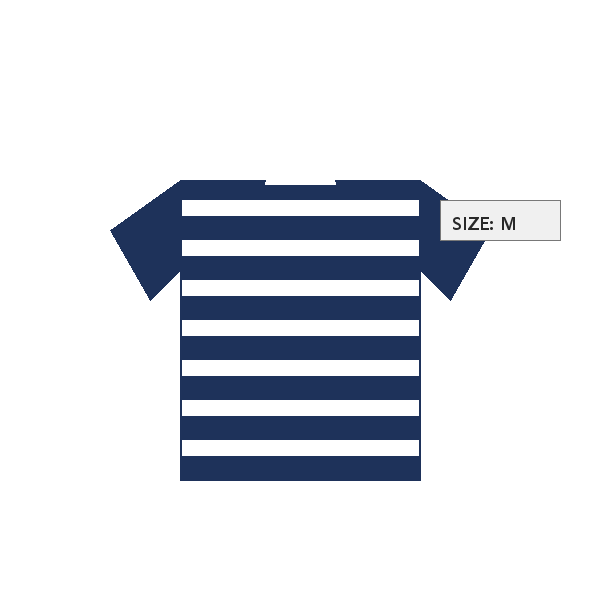

In [2]:
show(PRODUCT)

In [3]:
bad = ask(PRODUCT, "이 이미지를 설명해줘.")
print("[나쁜 예]\n", bad)

[나쁜 예]
 이 이미지는 단순한 아이콘 스타일의 티셔츠를 보여줍니다. 티셔츠는 **연필색(네이비 블루)**과 **흰색**으로 이루어진 수평 줄무늬 패턴을 가지고 있으며, 짧은 소매와 목 부분이 제작된 디자인입니다. 티셔츠의 오른쪽 옆면에는 "SIZE: M"이라는 글자가 적힌 작은 박스형 라벨이 붙어 있습니다. 배경은 깨끗한 흰색으로, 전체적으로 모던하고 간결한 벡터 아이콘 스타일로 제작되었습니다. 이 이미지는 의류 상품의 크기 정보를 표시하는 용도로 사용될 수 있으며, 특히 옷가짐 사이트나 제품 설명에서 흔히 나타납니다.


In [4]:
good = ask(
    PRODUCT,
    "이 상품 이미지를 온라인 쇼핑몰 상세페이지용 alt 텍스트로 쓸 수 있게, "
    "색상·소재·형태를 포함해 한국어 한 문장으로 설명해줘.",
)
print("[좋은 예]\n", good)

[좋은 예]
 남색과 흰색의 수평 줄무늬가 있는 짧은 소매 코튼 티셔츠로, M 사이즈입니다.


## OCR Prompt
"읽어줘" 대신 **"그대로 전사(transcribe)해줘"**라고 요청하면 임의 요약/의역이
줄어듭니다.

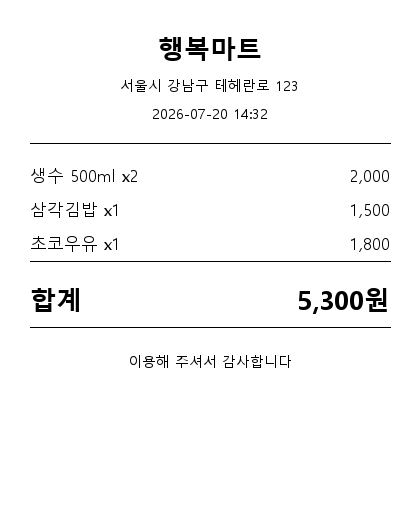

In [5]:
show(RECEIPT)

In [6]:
bad_ocr = ask(RECEIPT, "이 이미지에 뭐라고 써있어?")
print("[나쁜 예]\n", bad_ocr)

[나쁜 예]
 이 이미지는 다음 내용을 표시하고 있습니다:  

- **행복마트** (店名)  
- **서울시 강남구 테헤란로 123** (주소)  
- **2026-07-20 14:32** (날짜 및 시간)  
- **생수 500ml x2** → **2,000원**  
- **삼각김밥 x1** → **1,500원**  
- **초코우유 x1** → **1,800원**  
- **합계** → **5,300원**  
- **이용해 주셔서 감사합니다** (감사 메시지)  

### 설명:  
- "행복마트"는 한국어로 "행복 마트"로 뜻하며, 가격표 또는 구매 내역을 보여주는 스크린샷입니다.  
- **생수** = 물(500ml x2), **삼각김밥** = 삼각형 김밥(일반적인 한식 음식), **초코우유** = 초코 우유(치아우유)로 해석됩니다.  
- 총 금액은 "5,300원"으로 계산되어 있으며, 2026년 7월 20일의 날짜를 포함해 이는 실제 구매 내역을 담긴 예시로 보입니다.  
- **이용해 주셔서 감사합니다** = "감사합니다" 문구로 사용되며, 일반적인 서비스 후 감사 메시지입니다.


In [7]:
good_ocr = ask(
    RECEIPT,
    "이미지 속 모든 텍스트를 줄바꿈까지 그대로 전사해줘. "
    "읽을 수 없는 글자는 [?]로 표시하고, 임의로 고치거나 요약하지 마.",
)
print("[좋은 예]\n", good_ocr)

[좋은 예]
 행복마트
서울시 강남구 테헤란로 123
2026-07-20 14:32
생수 500ml x2
2,000
삼각김밥 x1
1,500
초코우유 x1
1,800
합계
5,300원
이용해 주셔서 감사합니다


## Reasoning Prompt
단순 인식이 아니라 **근거를 먼저 설명한 뒤 답을 제시**하도록 요청하면
할루시네이션이 줄어듭니다. "모르면 모른다"고 답하게 만드는 것도 중요합니다.

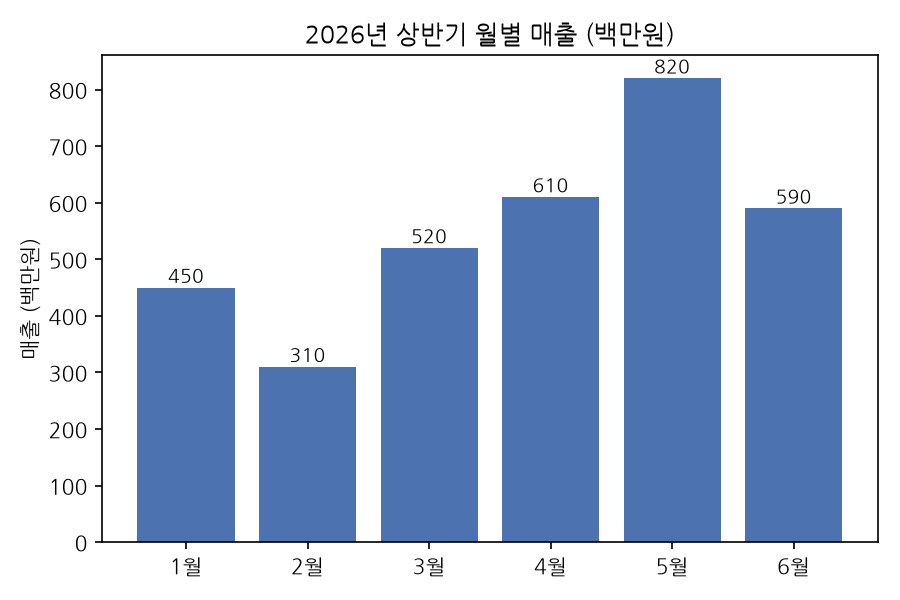

In [8]:
show(BAR_CHART)

In [9]:
reasoning = ask(
    BAR_CHART,
    "이 막대그래프에서 값이 가장 큰 달과 가장 작은 달의 차이를 계산해줘. "
    "판단 근거(그래프의 어느 막대를 비교했는지)를 먼저 설명한 뒤 답을 제시하고, "
    "그래프에 없는 값은 추정하지 말고 '확인 불가'라고 답해.",
)
print(reasoning)

**판단 근거**:  
이 막대그래프에서 5월(5월)의 매출 값이 820백만원으로 가장 높고, 2월(2월)의 매출 값이 310백만원으로 가장 낮습니다. 이 두 달의 막대를 비교하여 차이를 계산해야 합니다.

**계산**:  
가장 큰 값 (5월: 820) - 가장 작은 값 (2월: 310) = **510**  

**답변**: 510


## Structured Output
후속 처리가 가능하도록 **JSON 스키마를 예시와 함께 명시**하고,
`ollama`의 `format="json"` 옵션(`ask_json`)으로 파싱 가능한 응답을 강제합니다.

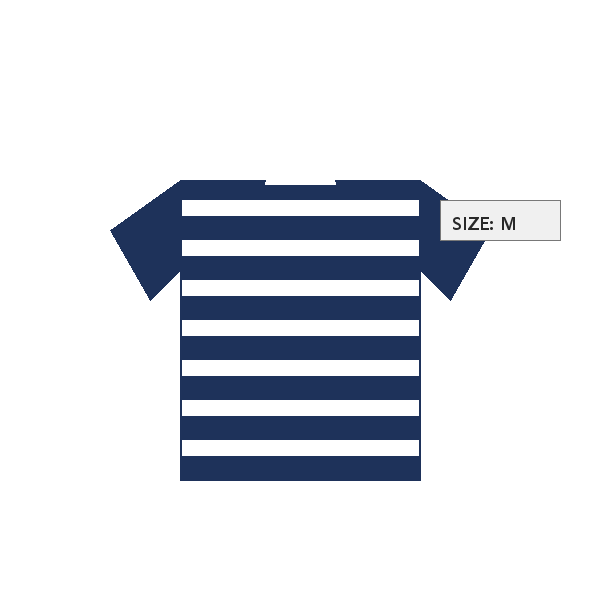

In [10]:
show(PRODUCT)

In [11]:
schema_prompt = '''
아래 JSON 스키마에 맞춰서만 답해. 다른 설명 문장은 출력하지 마.
{
  "category": "string",
  "color": "string",
  "pattern": "string",
  "size": "string"
}
'''
result = ask_json(PRODUCT, schema_prompt)
print(type(result), result)
assert set(result.keys()) >= {"category", "color", "pattern", "size"}

<class 'dict'> {'category': 'shirt', 'color': 'navy', 'pattern': 'horizontal stripes', 'size': 'M'}
